In [3]:
from google.colab import userdata
token = userdata.get('GITHUB_TOKEN')

REPO = "smart-waste-multi-agent"

%cd /content
!git clone https://{token}@github.com/Nafila1234/{REPO}.git
%cd /content/{REPO}
!git config user.name "Nafila1234"
!git config user.email "nafiladziri17@gmail.com"

/content
fatal: destination path 'smart-waste-multi-agent' already exists and is not an empty directory.
/content/smart-waste-multi-agent


In [4]:
from google.colab import drive
drive.mount('/content/drive')

%cd /content/{REPO}
!git pull

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/smart-waste-multi-agent
Already up to date.


In [5]:
!rm -rf /content/garbage
!mkdir -p /content/garbage
!unzip -q "/content/archive (1).zip" -d /content/garbage
!ls /content/garbage

battery  glass	metal  organic	paper  plastic


In [6]:
%cd /content/{REPO}

/content/smart-waste-multi-agent


 Train/validation/test split (70/15/15)

In [7]:
import os, glob, pandas as pd
from sklearn.model_selection import train_test_split

REPO = "smart-waste-multi-agent"
DATA_DIR = "/content/garbage"
classes = sorted(d for d in os.listdir(DATA_DIR)
                 if os.path.isdir(os.path.join(DATA_DIR, d)))

rows = []
for c in classes:
    for p in glob.glob(os.path.join(DATA_DIR, c, "*")):
        rows.append((f"{c}/{os.path.basename(p)}", c))
df = pd.DataFrame(rows, columns=["file", "label"])

train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df.label, random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df.label, random_state=42)

df.loc[train_df.index, "split"] = "train"
df.loc[val_df.index, "split"] = "val"
df.loc[test_df.index, "split"] = "test"
df.to_csv(f"/content/{REPO}/visual_agent/split.csv", index=False)

print(len(train_df), len(val_df), len(test_df))

3255 697 698


Data loading and augmentation

In [8]:
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image

torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

class_to_idx = {c: i for i, c in enumerate(classes)}
mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(0.2, 0.2, 0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

class GarbageDS(Dataset):
    def __init__(self, frame, tf):
        self.frame = frame.reset_index(drop=True)
        self.tf = tf
    def __len__(self):
        return len(self.frame)
    def __getitem__(self, i):
        r = self.frame.iloc[i]
        img = Image.open(os.path.join(DATA_DIR, r.file)).convert("RGB")
        return self.tf(img), class_to_idx[r.label]

train_dl = DataLoader(GarbageDS(train_df, train_tf), batch_size=32, shuffle=True, num_workers=2)
val_dl = DataLoader(GarbageDS(val_df, eval_tf), batch_size=32, num_workers=2)
test_dl = DataLoader(GarbageDS(test_df, eval_tf), batch_size=32, num_workers=2)

Device: cuda


Pretrained model (transfer learning)

In [9]:
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
for p in model.parameters():
    p.requires_grad = False                      # freeze the pretrained layers
model.fc = nn.Linear(model.fc.in_features, len(classes))   # new 6-class head
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.fc.parameters(), lr=1e-3)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 118MB/s]


Training

In [10]:
import copy
best_acc, best_state = 0, None

for epoch in range(8):
    model.train()
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        loss = criterion(model(x), y)
        loss.backward()
        optimizer.step()

    model.eval()
    correct = 0
    with torch.no_grad():
        for x, y in val_dl:
            x, y = x.to(device), y.to(device)
            correct += (model(x).argmax(1) == y).sum().item()
    val_acc = correct / len(val_df)
    print(f"Epoch {epoch+1}: val accuracy = {val_acc:.3f}")
    if val_acc > best_acc:
        best_acc, best_state = val_acc, copy.deepcopy(model.state_dict())

model.load_state_dict(best_state)

Epoch 1: val accuracy = 0.818
Epoch 2: val accuracy = 0.851
Epoch 3: val accuracy = 0.869
Epoch 4: val accuracy = 0.874
Epoch 5: val accuracy = 0.854
Epoch 6: val accuracy = 0.871
Epoch 7: val accuracy = 0.881
Epoch 8: val accuracy = 0.881


<All keys matched successfully>

Final evaluation on the test set

              precision    recall  f1-score   support

     battery       0.93      1.00      0.96       116
       glass       0.66      0.87      0.75       116
       metal       0.87      0.85      0.86       117
     organic       0.97      1.00      0.98       116
       paper       0.95      0.86      0.91       117
     plastic       0.91      0.62      0.74       116

    accuracy                           0.87       698
   macro avg       0.88      0.87      0.87       698
weighted avg       0.88      0.87      0.87       698



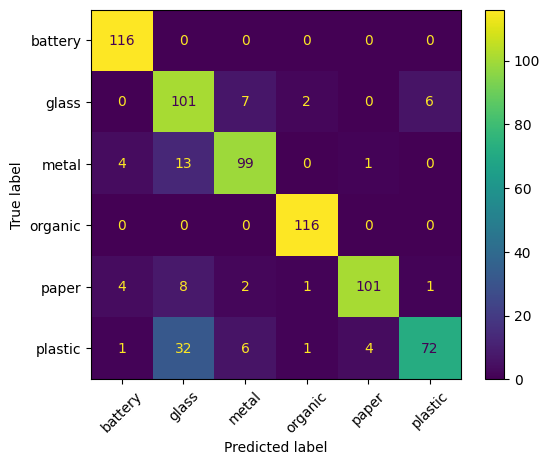

In [11]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

model.eval()
preds, truth = [], []
with torch.no_grad():
    for x, y in test_dl:
        preds += model(x.to(device)).argmax(1).cpu().tolist()
        truth += y.tolist()

print(classification_report(truth, preds, target_names=classes))
ConfusionMatrixDisplay.from_predictions(truth, preds, display_labels=classes, xticks_rotation=45)
plt.show()

Save the model to Drive

In [12]:
os.makedirs("/content/drive/MyDrive/DM_Project", exist_ok=True)
torch.save(model.state_dict(), "/content/drive/MyDrive/DM_Project/vision_agent_resnet18.pth")

Save the notebook and the split to GitHub

In [13]:
%cd /content/{REPO}
!git pull
!cp "/content/drive/MyDrive/Colab Notebooks/02_cnn_baseline.ipynb" visual_agent/
!git add .
!git commit -m "Add ResNet18 baseline and train/val/test split"
!git push

/content/smart-waste-multi-agent
Already up to date.
cp: cannot stat '/content/drive/MyDrive/Colab Notebooks/02_cnn_baseline.ipynb': No such file or directory
[main e914190] Add ResNet18 baseline and train/val/test split
 1 file changed, 4651 insertions(+)
 create mode 100644 visual_agent/split.csv
Enumerating objects: 6, done.
Counting objects: 100% (6/6), done.
Delta compression using up to 2 threads
Compressing objects: 100% (4/4), done.
Writing objects: 100% (4/4), 14.01 KiB | 2.80 MiB/s, done.
Total 4 (delta 2), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (2/2), completed with 2 local objects.
To https://github.com/Nafila1234/smart-waste-multi-agent.git
   54f619f..e914190  main -> main


fine-tune the last block

In [14]:
# unfreeze the last ResNet block, keep a small learning rate for it
for p in model.layer4.parameters():
    p.requires_grad = True

optimizer = torch.optim.Adam([
    {"params": model.layer4.parameters(), "lr": 1e-4},
    {"params": model.fc.parameters(),     "lr": 1e-3},
])

best_acc, best_state = 0, None
for epoch in range(10):
    model.train()
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        criterion(model(x), y).backward()
        optimizer.step()

    model.eval()
    correct = 0
    with torch.no_grad():
        for x, y in val_dl:
            x, y = x.to(device), y.to(device)
            correct += (model(x).argmax(1) == y).sum().item()
    val_acc = correct / len(val_df)
    print(f"Epoch {epoch+1}: val accuracy = {val_acc:.3f}")
    if val_acc > best_acc:
        best_acc, best_state = val_acc, copy.deepcopy(model.state_dict())

model.load_state_dict(best_state)

Epoch 1: val accuracy = 0.908
Epoch 2: val accuracy = 0.920
Epoch 3: val accuracy = 0.925
Epoch 4: val accuracy = 0.928
Epoch 5: val accuracy = 0.928
Epoch 6: val accuracy = 0.921
Epoch 7: val accuracy = 0.943
Epoch 8: val accuracy = 0.937
Epoch 9: val accuracy = 0.935
Epoch 10: val accuracy = 0.918


<All keys matched successfully>

evaluation

              precision    recall  f1-score   support

     battery       0.98      0.99      0.99       116
       glass       0.88      0.91      0.89       116
       metal       0.91      0.94      0.92       117
     organic       0.97      0.99      0.98       116
       paper       0.99      0.97      0.98       117
     plastic       0.94      0.88      0.91       116

    accuracy                           0.95       698
   macro avg       0.95      0.95      0.95       698
weighted avg       0.95      0.95      0.95       698



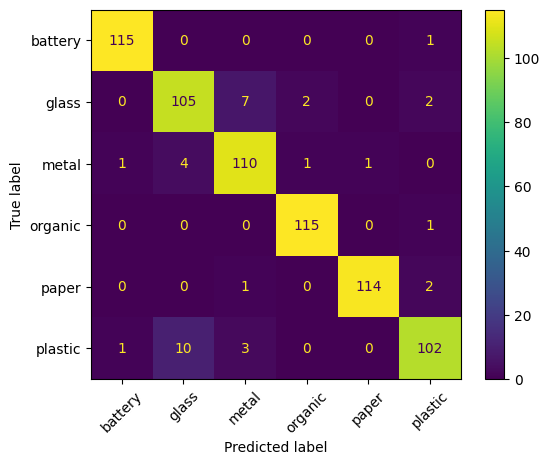

In [15]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

model.eval()
preds, truth = [], []
with torch.no_grad():
    for x, y in test_dl:
        preds += model(x.to(device)).argmax(1).cpu().tolist()
        truth += y.tolist()

print(classification_report(truth, preds, target_names=classes))
ConfusionMatrixDisplay.from_predictions(truth, preds, display_labels=classes, xticks_rotation=45)
plt.show()

save the new weights

In [18]:
torch.save(model.state_dict(), "/content/drive/MyDrive/DM_Project/vision_agent_resnet18_finetuned.pth")

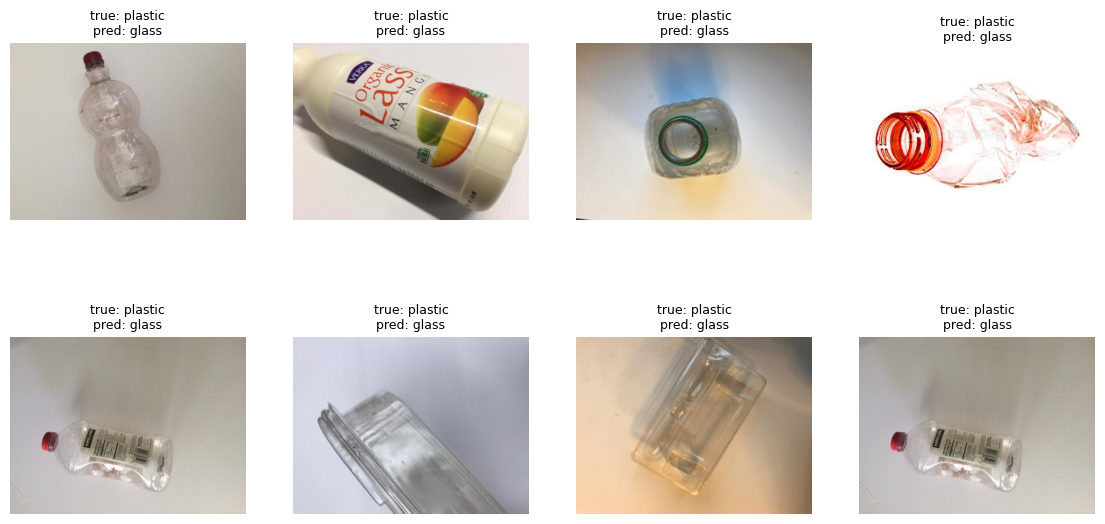

In [19]:
import numpy as np
glass_idx, plastic_idx = class_to_idx["glass"], class_to_idx["plastic"]
test_files = test_df.reset_index(drop=True)

wrong = [i for i, (t, p) in enumerate(zip(truth, preds))
         if t == plastic_idx and p == glass_idx][:8]

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, i in zip(axes.flatten(), wrong):
    img = Image.open(os.path.join(DATA_DIR, test_files.iloc[i].file))
    ax.imshow(img)
    ax.set_title("true: plastic\npred: glass", fontsize=9)
    ax.axis("off")
plt.show()

In [20]:
import hashlib
def md5(path):
    return hashlib.md5(open(path, "rb").read()).hexdigest()

df["hash"] = [md5(os.path.join(DATA_DIR, f)) for f in df.file]
dups = df[df.duplicated("hash", keep=False)]
print("Images with an exact duplicate:", len(dups))

# duplicates that cross the train/test boundary
g = df.groupby("hash")["split"].nunique()
print("Duplicate groups spread over several splits:", (g > 1).sum())

Images with an exact duplicate: 546
Duplicate groups spread over several splits: 136


Check for conflicting labels

In [21]:
conflict = df.groupby("hash")["label"].nunique()
print("Duplicate groups with different labels:", (conflict > 1).sum())

Duplicate groups with different labels: 3


Deduplicate and re-split

In [22]:
bad_hashes = conflict[conflict > 1].index
clean = (df[~df.hash.isin(bad_hashes)]
         .drop_duplicates("hash")[["file", "label", "hash"]]
         .reset_index(drop=True))
print(len(df), "->", len(clean))
print(clean.label.value_counts())

train_df, temp_df = train_test_split(clean, test_size=0.30, stratify=clean.label, random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df.label, random_state=42)

clean.loc[train_df.index, "split"] = "train"
clean.loc[val_df.index, "split"] = "val"
clean.loc[test_df.index, "split"] = "test"
clean.to_csv("/content/smart-waste-multi-agent/visual_agent/split_dedup.csv", index=False)

# sanity check: no identical image in two different splits
sets = [set(d.hash) for d in (train_df, val_df, test_df)]
print("Overlap:", len(sets[0] & sets[1]), len(sets[0] & sets[2]), len(sets[1] & sets[2]))

4650 -> 4373
label
battery    775
organic    775
glass      772
plastic    721
metal      717
paper      613
Name: count, dtype: int64
Overlap: 0 0 0


Rebuild the data loaders

In [23]:
train_dl = DataLoader(GarbageDS(train_df, train_tf), batch_size=32, shuffle=True, num_workers=2)
val_dl = DataLoader(GarbageDS(val_df, eval_tf), batch_size=32, num_workers=2)
test_dl = DataLoader(GarbageDS(test_df, eval_tf), batch_size=32, num_workers=2)

Retrain from scratch (both stages in one cell)

In [24]:
def run_epochs(model, optimizer, n_epochs):
    best_acc, best_state = 0, None
    for epoch in range(n_epochs):
        model.train()
        for x, y in train_dl:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            criterion(model(x), y).backward()
            optimizer.step()
        model.eval()
        correct = 0
        with torch.no_grad():
            for x, y in val_dl:
                x, y = x.to(device), y.to(device)
                correct += (model(x).argmax(1) == y).sum().item()
        val_acc = correct / len(val_df)
        print(f"  epoch {epoch+1}: val accuracy = {val_acc:.3f}")
        if val_acc > best_acc:
            best_acc, best_state = val_acc, copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    return best_acc

torch.manual_seed(42)
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
for p in model.parameters():
    p.requires_grad = False
model.fc = nn.Linear(model.fc.in_features, len(classes))
model = model.to(device)

print("Stage 1: head only")
opt = torch.optim.Adam(model.fc.parameters(), lr=1e-3)
acc1 = run_epochs(model, opt, 6)

print("Stage 2: unfreeze last block")
for p in model.layer4.parameters():
    p.requires_grad = True
opt = torch.optim.Adam([
    {"params": model.layer4.parameters(), "lr": 1e-4},
    {"params": model.fc.parameters(), "lr": 1e-3},
])
acc2 = run_epochs(model, opt, 8)
print("Best validation accuracy:", acc1, acc2)

Stage 1: head only
  epoch 1: val accuracy = 0.788
  epoch 2: val accuracy = 0.840
  epoch 3: val accuracy = 0.857
  epoch 4: val accuracy = 0.867
  epoch 5: val accuracy = 0.872
  epoch 6: val accuracy = 0.854
Stage 2: unfreeze last block
  epoch 1: val accuracy = 0.893
  epoch 2: val accuracy = 0.915
  epoch 3: val accuracy = 0.945
  epoch 4: val accuracy = 0.938
  epoch 5: val accuracy = 0.951
  epoch 6: val accuracy = 0.928
  epoch 7: val accuracy = 0.936
  epoch 8: val accuracy = 0.931
Best validation accuracy: 0.8719512195121951 0.9512195121951219


Evaluate on the new test set

              precision    recall  f1-score   support

     battery       0.97      0.98      0.98       117
       glass       0.91      0.91      0.91       116
       metal       0.91      0.91      0.91       107
     organic       0.97      0.99      0.98       116
       paper       0.96      0.97      0.96        92
     plastic       0.87      0.83      0.85       108

    accuracy                           0.93       656
   macro avg       0.93      0.93      0.93       656
weighted avg       0.93      0.93      0.93       656



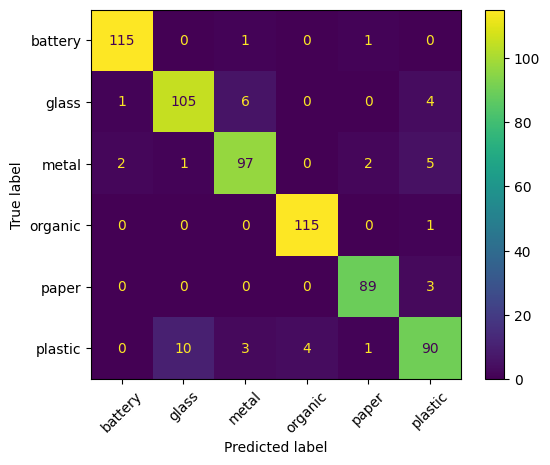

In [25]:
model.eval()
preds, truth = [], []
with torch.no_grad():
    for x, y in test_dl:
        preds += model(x.to(device)).argmax(1).cpu().tolist()
        truth += y.tolist()

print(classification_report(truth, preds, target_names=classes))
ConfusionMatrixDisplay.from_predictions(truth, preds, display_labels=classes, xticks_rotation=45)
plt.show()

torch.save(model.state_dict(), "/content/drive/MyDrive/DM_Project/vision_agent_resnet18_dedup.pth")

In [27]:
%cd /content/smart-waste-multi-agent
!git pull
!cp "/content/drive/MyDrive/Colab Notebooks/02_cnn_baseline.ipynb" visual_agent/
!git add .
!git commit -m "Remove duplicate images, re-split and retrain vision agent"
!git push

/content/smart-waste-multi-agent
Already up to date.
cp: cannot stat '/content/drive/MyDrive/Colab Notebooks/02_cnn_baseline.ipynb': No such file or directory
On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean
Everything up-to-date
